# Car Purchase Prediction using Machine Learning

Binary classification: Predict whether a customer buys a newly launched SUV from **Age** and **Estimated Salary** (400 customers, `Purchased` = 0/1). Seven classifiers are trained on a 75/25 split (`random_state = 42`) and compared on the 100-row test set.

- Dataset: `data/Social_Network_Ads.csv` (see `data/README.md`).
- Summary of results, cross-validation and caveats: see the repository `README.md`.
- Logistic Regression, KNN and linear SVM are implemented both from scratch (NumPy) and with scikit-learn.


# **1) Exploratory Data Analysis (EDA)**

---



## Importing the libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Importing the dataset

In [ ]:
import os

DATA_PATH = "data/Social_Network_Ads.csv"
df = pd.read_csv(DATA_PATH)
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

## Extracting valuable information from the dataset

In [ ]:
df.shape

(400, 3)

In [ ]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [ ]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              400 non-null    int64
 1   EstimatedSalary  400 non-null    int64
 2   Purchased        400 non-null    int64
dtypes: int64(3)
memory usage: 9.5 KB


In [ ]:
df.isnull().sum()

Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [ ]:
# Imputation
'''
from sklearn.impute import SimpleImputer
imp = SimpleImputer(missing_values = np.nan, strategy = 'mean')
imp.fit(X[:, 0:2])
X[:, 1:3] = imp.transform(X[:, 0:2])
'''

"\nfrom sklearn.impute import SimpleImputer\nimp = SimpleImputer(missing_values = np.nan, strategy = 'mean')\nimp.fit(X[:, 0:2])\nX[:, 1:3] = imp.transform(X[:, 0:2])\n"

## Visualising the dataset

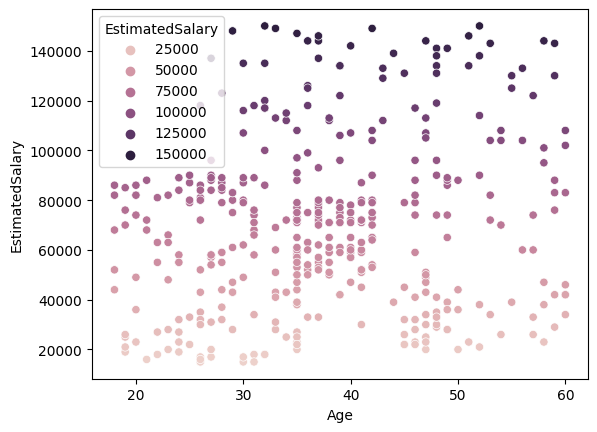

In [ ]:
sns.scatterplot(data = df, x = 'Age', y = 'EstimatedSalary', hue = 'EstimatedSalary')
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/axisgrid.py:1507: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.10/dist-packages/seaborn/axisgrid.py:1507: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.10/dist-packages/seaborn/axisgrid.py:1609: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/usr/local/lib/python3.10/dist-packages/seaborn/axisgrid.py:1609: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)


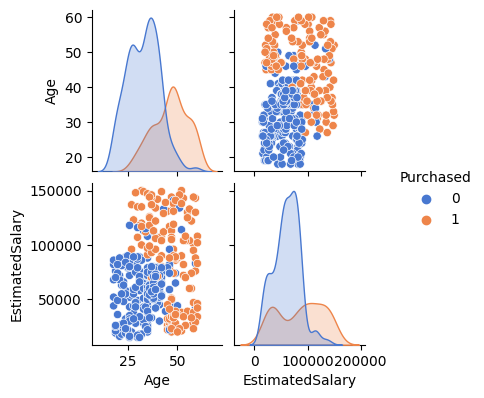

In [ ]:
sns.pairplot(df, hue = 'Purchased', palette = sns.color_palette('muted', 3), height = 2);

## Detecting outliers in the dataset

In [ ]:
# ML classification algorithms like 'Logistic Regression' are insensitive to outliers
# while algorithms like 'KNN' are highly sensitive to them!

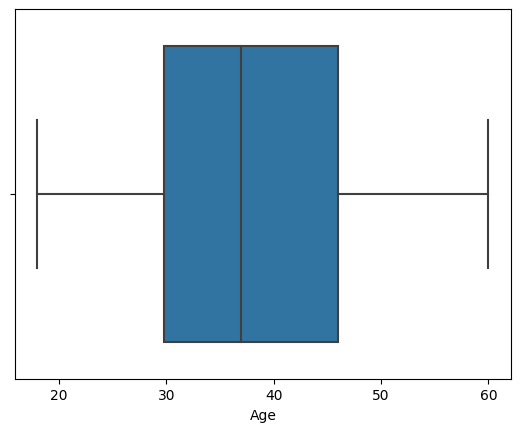

In [ ]:
sns.boxplot(data = df, x = 'Age')
plt.show()

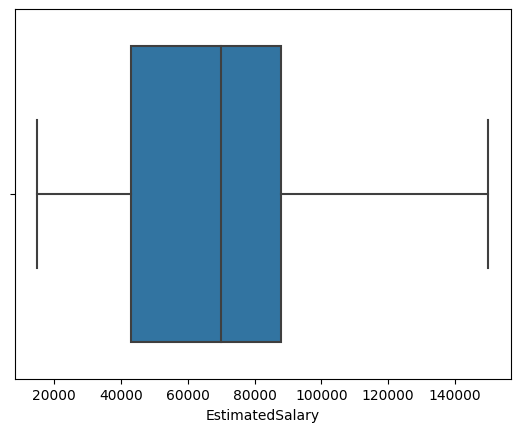

In [ ]:
sns.boxplot(data = df, x = 'EstimatedSalary')
plt.show()

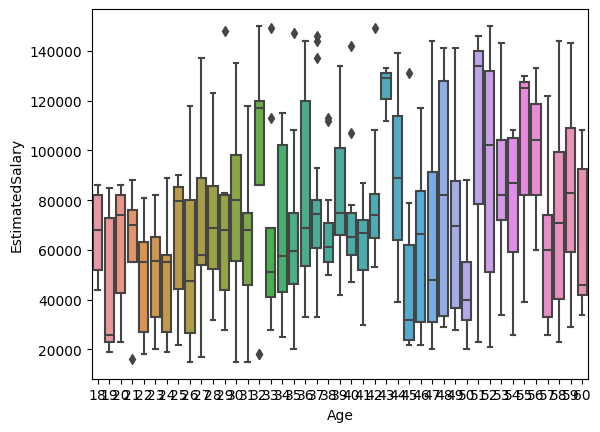

In [ ]:
sns.boxplot(data = df, x = 'Age', y = 'EstimatedSalary')
plt.show()

## Feature Selection

In [ ]:
def chart_correlation(data, method = 'pearson'):
    # Calculate the correlation among the columns
    df_corr = df.corr(method = method)

    # Using only two decimal places so that it increases the readability
    with pd.option_context('display.precision', 2):

      # Use a sea green color palette
      cm = sns.light_palette("seagreen", as_cmap = True)

      # 'X_corr' is all the method needs to return but styling makes it look nicer

      return(df_corr.style.background_gradient(cmap = cm, low = -0.6, high = 0.2).set_caption(f'{method} correlation coefficient'))

In [ ]:
'''
|r| = 0.00 --> No association
0.00 < |r| <= 0.25 --> Negligible association
0.25 < |r| <= 0.50 --> Weak association
0.50 < |r| <= 0.75 --> Moderate association
0.75 < |r| <  1.00 --> Very strong association
|r| = 1.00 --> Perfect association
'''
chart_correlation(df, 'pearson') # 'r' belongs to [-1, 1]

,Age,EstimatedSalary,Purchased
Age,1.000000,0.155238,0.622454
EstimatedSalary,0.155238,1.000000,0.362083
Purchased,0.622454,0.362083,1.000000


## Splitting the dataset into the Training set and Test set

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [ ]:
print(X_train)

[[    57 122000]
 [    39  71000]
 [    47  25000]
 [    24  19000]
 [    36  50000]
 [    32 150000]
 [    48  29000]
 [    30 107000]
 [    60  34000]
 [    38  61000]
 [    33  31000]
 [    39  71000]
 [    55  39000]
 [    49  39000]
 [    43 112000]
 [    27  20000]
 [    26  17000]
 [    37  93000]
 [    42  54000]
 [    35  61000]
 [    29  75000]
 [    38  80000]
 [    45  26000]
 [    54 108000]
 [    46  23000]
 [    23  28000]
 [    37  75000]
 [    42  65000]
 [    35  71000]
 [    51 146000]
 [    39  96000]
 [    24  89000]
 [    58  95000]
 [    25  22000]
 [    41  59000]
 [    28  89000]
 [    42  80000]
 [    42 108000]
 [    46  96000]
 [    47 113000]
 [    33  28000]
 [    19  25000]
 [    49  89000]
 [    31  15000]
 [    30  79000]
 [    48 141000]
 [    32 117000]
 [    37  71000]
 [    18  86000]
 [    42  79000]
 [    27  84000]
 [    40  65000]
 [    57  74000]
 [    26  15000]
 [    26  80000]
 [    29  43000]
 [    33 149000]
 [    39  42000]
 [    54 10400

In [ ]:
print(y_train)

[1 0 1 0 0 1 1 1 1 0 0 0 1 1 1 0 0 1 0 0 0 0 1 1 1 0 0 0 0 1 1 0 1 0 0 0 1
 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 1 0 0 0 1 0 0 1 1 0 0 0 1 1 0 1 1 0 1 1 1 0 0 1 1 1 0 0 0 0 0 1
 0 0 0 1 0 0 1 1 1 1 0 1 0 0 0 0 1 0 1 0 0 0 1 0 0 0 1 1 1 1 0 0 0 0 0 1 0
 1 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 0 0 1 0 1
 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 0 0 0
 1 0 1 1 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 1 0 1 1 0 0 1
 0 1 0 0 0 0 1 0 0 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0
 0 0 0 0]


In [ ]:
print(X_test)

[[    46  22000]
 [    59  88000]
 [    28  44000]
 [    48  96000]
 [    29  28000]
 [    30  62000]
 [    47 107000]
 [    29  83000]
 [    40  75000]
 [    42  65000]
 [    35  65000]
 [    53  34000]
 [    23  48000]
 [    20  23000]
 [    30  87000]
 [    35 108000]
 [    52  38000]
 [    46  74000]
 [    39  42000]
 [    56  60000]
 [    22  27000]
 [    29  80000]
 [    47  23000]
 [    59  76000]
 [    19  19000]
 [    51  23000]
 [    42  80000]
 [    37  53000]
 [    55 125000]
 [    19  21000]
 [    46  41000]
 [    19  70000]
 [    36 144000]
 [    28  79000]
 [    40 107000]
 [    35  75000]
 [    37  55000]
 [    38  65000]
 [    26  30000]
 [    18  68000]
 [    48  33000]
 [    24  55000]
 [    18  52000]
 [    47  20000]
 [    20  49000]
 [    44 139000]
 [    29  61000]
 [    31  71000]
 [    48  41000]
 [    34  43000]
 [    25  79000]
 [    53  82000]
 [    38  55000]
 [    25  80000]
 [    37  80000]
 [    27  31000]
 [    60 102000]
 [    26 118000]
 [    31  7400

In [ ]:
print(y_test)

[0 1 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 1 1 0 1 0 0 1 0 1 0 1 0 1 0 0
 0 0 0 1 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 1 1 1 0 0 1 0 0 0
 1 0 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 0 0 0 0 0 1 0 1 1]


## Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [ ]:
print(X_train)

[[ 1.8925893   1.52189404]
 [ 0.1250379   0.03213212]
 [ 0.9106163  -1.31157471]
 [-1.34792161 -1.48684082]
 [-0.169554   -0.58129926]
 [-0.56234321  2.33980255]
 [ 1.0088136  -1.19473064]
 [-0.75873781  1.08372877]
 [ 2.1871812  -1.04867555]
 [ 0.0268406  -0.25997806]
 [-0.46414591 -1.1363086 ]
 [ 0.1250379   0.03213212]
 [ 1.6961947  -0.90262046]
 [ 1.1070109  -0.90262046]
 [ 0.5178271   1.22978386]
 [-1.05332971 -1.4576298 ]
 [-1.15152701 -1.54526286]
 [-0.0713567   0.67477452]
 [ 0.4196298  -0.46445519]
 [-0.2677513  -0.25997806]
 [-0.85693511  0.14897619]
 [ 0.0268406   0.29503128]
 [ 0.7142217  -1.28236369]
 [ 1.5979974   1.11293979]
 [ 0.812419   -1.36999675]
 [-1.44611891 -1.22394166]
 [-0.0713567   0.14897619]
 [ 0.4196298  -0.14313399]
 [-0.2677513   0.03213212]
 [ 1.3034055   2.22295848]
 [ 0.1250379   0.76240757]
 [-1.34792161  0.55793045]
 [ 1.9907866   0.73319655]
 [-1.24972431 -1.39920777]
 [ 0.3214325  -0.3184001 ]
 [-0.95513241  0.55793045]
 [ 0.4196298   0.29503128]
 

In [ ]:
print(X_test)

[[ 0.812419   -1.39920777]
 [ 2.0889839   0.52871943]
 [-0.95513241 -0.75656537]
 [ 1.0088136   0.76240757]
 [-0.85693511 -1.22394166]
 [-0.75873781 -0.23076704]
 [ 0.9106163   1.08372877]
 [-0.85693511  0.38266434]
 [ 0.2232352   0.14897619]
 [ 0.4196298  -0.14313399]
 [-0.2677513  -0.14313399]
 [ 1.4998001  -1.04867555]
 [-1.44611891 -0.6397213 ]
 [-1.74071081 -1.36999675]
 [-0.75873781  0.49950841]
 [-0.2677513   1.11293979]
 [ 1.4016028  -0.93183148]
 [ 0.812419    0.11976517]
 [ 0.1250379  -0.8149874 ]
 [ 1.794392   -0.28918908]
 [-1.54431621 -1.25315268]
 [-0.85693511  0.29503128]
 [ 0.9106163  -1.36999675]
 [ 2.0889839   0.17818721]
 [-1.83890811 -1.48684082]
 [ 1.3034055  -1.36999675]
 [ 0.4196298   0.29503128]
 [-0.0713567  -0.49366621]
 [ 1.6961947   1.6095271 ]
 [-1.83890811 -1.42841878]
 [ 0.812419   -0.84419842]
 [-1.83890811  0.0029211 ]
 [-0.169554    2.16453644]
 [-0.95513241  0.26582026]
 [ 0.2232352   1.08372877]
 [-0.2677513   0.14897619]
 [-0.0713567  -0.43524417]
 

# **2) Model Building (Training and Testing)**

---

## **i) Algorithm 1: Logistic Regression (LoR)**

## Part 1: Implementation from scratch

In [ ]:
def sigmoid(x):

    return 1 / (1 + np.exp(-x))

class LogisticRegression():

    def __init__(self, lr = 0.01, n_itrs = 5000):
        self.lr = lr
        self.n_itrs = n_itrs
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.random.rand(n_features)
        self.bias = 0

        # Gradient Descent
        for i in range(self.n_itrs):
            linear_pred = np.dot(X, self.weights) + self.bias
            predictions = sigmoid(linear_pred)
            dw = (1 / n_samples) * np.dot(X.T, (predictions - y))
            db = (1 / n_samples) * np.sum(predictions - y)
            self.weights = self.weights - (self.lr * dw)
            self.bias = self.bias - (self.lr * db)

    def predict(self, X):
        linear_pred = np.dot(X, self.weights) + self.bias
        y_pred = sigmoid(linear_pred)
        class_pred = [0 if y<=0.5 else 1 for y in y_pred]

        return class_pred

In [ ]:
clfr = LogisticRegression()
clfr.fit(X_train, y_train)

## Part 2: Implementation using inbuilt library functions

### Training the LoR model on the Training set

In [ ]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 42)
classifier.fit(X_train, y_train)

LogisticRegression(random_state=42)

## Part 3: Model Prediction

### Predicting a new result

In [ ]:
print(clfr.predict(sc.transform([[42, 70000]])))
print(classifier.predict(sc.transform([[42, 70000]])))

[0]
[0]


### Predicting the Test set results

In [ ]:
y_pred = classifier.predict(X_test)
print(np.concatenate((y_pred.reshape(len(y_pred), 1), y_test.reshape(len(y_test), 1)), 1))

[[0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [1 1]
 [0 0]
 [0 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [0 1]
 [1 1]
 [0 0]
 [1 1]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 1]]


## Part 4: Visualising the results and the decision boundary

### Visualising the Training set results

<ipython-input-31-8112f02b3357>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


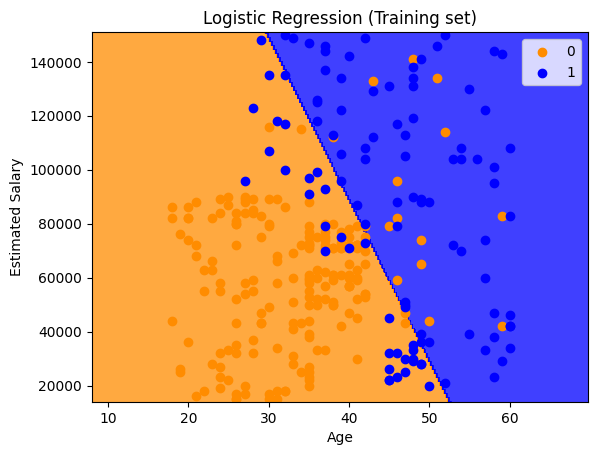

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_train), y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Logistic Regression (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

### Visualising the Test set results

<ipython-input-32-6b2f57dd30a7>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


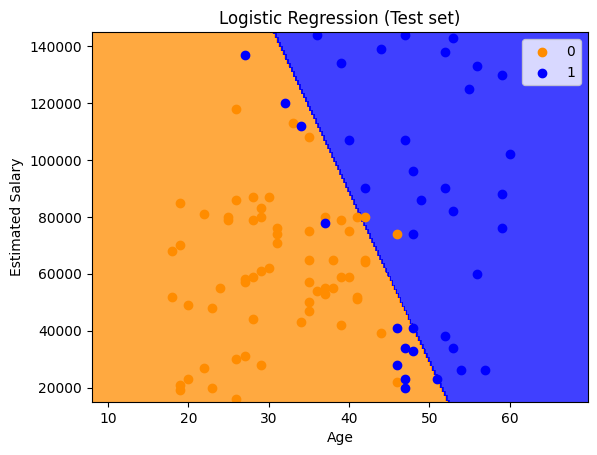

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_test), y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Logistic Regression (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

## Part 5: Evaluating the model using various metrics

### Making the Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[61  2]
 [12 25]]


### Calculating various evaluation metrics using the Confusion Matrix

In [ ]:
# P = TP + FN and N = TN + FP

In [ ]:
# Accuracy Ratio
# ACC = (TP + TN) / (P + N)
accuracy_score(y_test, y_pred)

0.86

In [ ]:
# Precision
# TPR = TP / (TP + FP)
precision_score(y_test, y_pred)

0.9259259259259259

In [ ]:
# Recall / Sensitivity / True Positive Rate (TPR)
# TPR = (TP / P) = TP / (TP + FN)
recall_score(y_test, y_pred)

0.6756756756756757

In [ ]:
# F1 Score (Harmonic Mean of Precision and Recall)
# F1 = 2*P*R / (P + R) = 2*TP / (2*TP + FP + FN)
f1_score(y_test, y_pred)

0.7812500000000001

## **ii) Algorithm 2: K-Nearest Neighbors (KNN)**

## Part 1: Implementation from scratch

In [ ]:
from collections import Counter

def euclidean_distance(x1, x2):
    distance = np.sqrt(np.sum((x1 - x2) ** 2))

    return distance

class KNN:

    def __init__(self, k = 5):
        self.k = k

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, X):
        predictions = [self._predict(x) for x in X]

        return predictions

    def _predict(self, x):

        # Compute the distance
        distances = [euclidean_distance(x, x_train) for x_train in self.X_train]

        # Get the nearest k neighbors
        k_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = [self.y_train[i] for i in k_indices]

        # Majority vote
        most_common = Counter(k_nearest_labels).most_common()

        return most_common[0][0]

In [ ]:
clfr = KNN()
clfr.fit(X_train, y_train)

## Part 2: Implementation using inbuilt library functions

### Training the KNN model on the Training set

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors = 5, metric = 'minkowski', p = 2) # Euclidean Distance
classifier.fit(X_train, y_train)

KNeighborsClassifier()

## Part 3: Model Prediction

### Predicting a new result

In [ ]:
print(clfr.predict(sc.transform([[42, 70000]])))
print(classifier.predict(sc.transform([[42, 70000]])))

[0]
[0]


### Predicting the Test set results

In [ ]:
y_pred = classifier.predict(X_test)
print(np.concatenate((y_pred.reshape(len(y_pred), 1), y_test.reshape(len(y_test), 1)), 1))

[[1 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [1 0]
 [1 1]
 [0 1]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]]


## Part 4: Visualising the results and the decision boundary

### Visualising the Training set results

<ipython-input-44-80352ca1107b>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


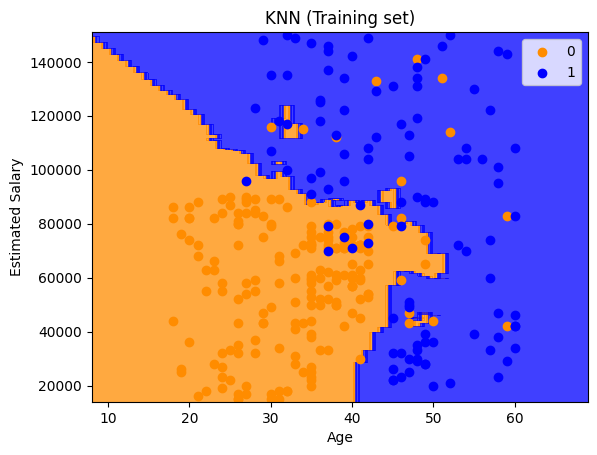

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_train), y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 1),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('KNN (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

### Visualising the Test set results

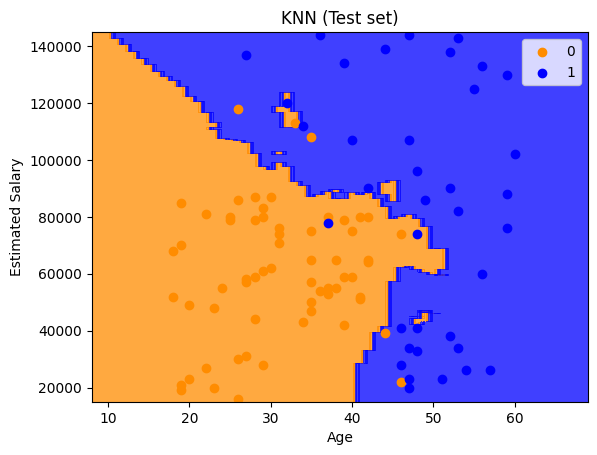

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_test), y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 1),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('KNN (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

## Part 5: Evaluating the model using various metrics

### Making the Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[59  4]
 [ 3 34]]


### Calculating various evaluation metrics using the Confusion Matrix

In [ ]:
# P = TP + FN and N = TN + FP

In [ ]:
# Accuracy Ratio
# ACC = (TP + TN) / (P + N)
accuracy_score(y_test, y_pred)

0.93

In [ ]:
# Precision
# TPR = TP / (TP + FP)
precision_score(y_test, y_pred)

0.8947368421052632

In [ ]:
# Recall / Sensitivity / True Positive Rate (TPR)
# TPR = (TP / P) = TP / (TP + FN)
recall_score(y_test, y_pred)

0.918918918918919

In [ ]:
# F1 Score (Harmonic Mean of Precision and Recall)
# F1 = 2*P*R / (P + R) = 2*TP / (2*TP + FP + FN)
f1_score(y_test, y_pred)

0.9066666666666667

## **iii) Algorithm 3: Support Vector Machine (SVM)**

## Part 1: Implementation from scratch

In [ ]:
'''
w * xi - b >= 1 , if yi = 1 (class 1)
w * xi - b = 0 , equation of the maximum margin hyperplane itself
w * xi - b <= -1 , if yi = -1 (class 0)
yi * (w * xi - b) >= 1 , yi belongs to {-1, 1}
'''

class SVM:

    def __init__(self, lr = 0.01, lambda_param = 0.01, n_itrs = 5000):
        self.lr = lr
        self.lambda_param = lambda_param
        self.n_itrs = n_itrs
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        y_ = np.where(y <= 0, -1, 1)

        # Initialise the weights
        self.weights = np.random.rand(n_features)
        self.bias = 0

        for i in range(self.n_itrs):
            for idx, xi in enumerate(X):
                condition = y_[idx] * (np.dot(xi, self.weights) - self.bias) >= 1
                if condition:
                    self.weights -= self.lr * (2 * self.lambda_param * self.weights)
                else:
                    self.weights -= self.lr * (2 * self.lambda_param * self.weights - np.dot(xi, y_[idx]))
                    self.bias -= self.lr * y_[idx]


    def predict(self, X):
        approx = np.dot(X, self.weights) - self.bias

        return np.sign(approx)

In [ ]:
clfr = SVM()
clfr.fit(X_train, y_train)

## Part 2: Implementation using inbuilt library functions

### Training the SVM model on the Training set

In [ ]:
from sklearn.svm import SVC
classifier = SVC(kernel = 'linear', random_state = 42)
classifier.fit(X_train, y_train)

SVC(kernel='linear', random_state=42)

## Part 3: Model Prediction

### Predicting a new result

In [ ]:
pred = clfr.predict(sc.transform([[42, 70000]]))
print(np.where(pred == -1, 0, 1))
print(classifier.predict(sc.transform([[42, 70000]])))

[0]
[0]


### Predicting the Test set results

In [ ]:
y_pred = classifier.predict(X_test)
print(np.concatenate((y_pred.reshape(len(y_pred), 1), y_test.reshape(len(y_test), 1)), 1))

[[0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [1 1]
 [0 0]
 [0 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [0 1]
 [1 1]
 [0 0]
 [1 1]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 1]]


## Part 4: Visualising the results and the decision boundary

### Visualising the Training set results

<ipython-input-57-113d773c9c77>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


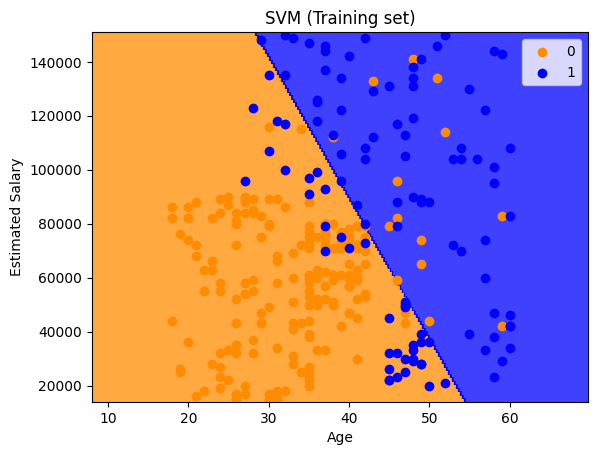

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_train), y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('SVM (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

### Visualising the Test set results

<ipython-input-58-a7ca7b58263c>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


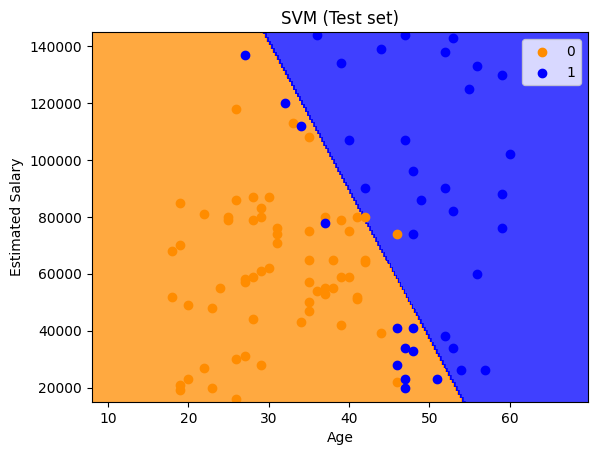

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_test), y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('SVM (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

## Part 5: Evaluating the model using various metrics

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[61  2]
 [12 25]]


### Calculating various evaluation metrics using the Confusion Matrix

In [ ]:
# P = TP + FN and N = TN + FP

In [ ]:
# Accuracy Ratio
# ACC = (TP + TN) / (P + N)
accuracy_score(y_test, y_pred)

0.86

In [ ]:
# Precision
# TPR = TP / (TP + FP)
precision_score(y_test, y_pred)

0.9259259259259259

In [ ]:
# Recall / Sensitivity / True Positive Rate (TPR)
# TPR = (TP / P) = TP / (TP + FN)
recall_score(y_test, y_pred)

0.6756756756756757

In [ ]:
# F1 Score (Harmonic Mean of Precision and Recall)
# F1 = 2*P*R / (P + R) = 2*TP / (2*TP + FP + FN)
f1_score(y_test, y_pred)

0.7812500000000001

# **3) Advanced ML Algorithms**

---

## **i) Algorithm 1: Kernel SVM**

## Part 1: Implementation

### Training the Kernel SVM model on the Training set

In [ ]:
from sklearn.svm import SVC
classifier = SVC(kernel = 'rbf', random_state = 42)
classifier.fit(X_train, y_train)

SVC(random_state=42)

## Part 2: Model Prediction

### Predicting the Test set results

In [ ]:
y_pred = classifier.predict(X_test)
print(np.concatenate((y_pred.reshape(len(y_pred), 1), y_test.reshape(len(y_test), 1)), 1))

[[1 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 0]
 [1 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [1 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [1 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]]


## Part 3: Visualisation

### Visualising the Training set results

<ipython-input-67-5234e10467bb>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


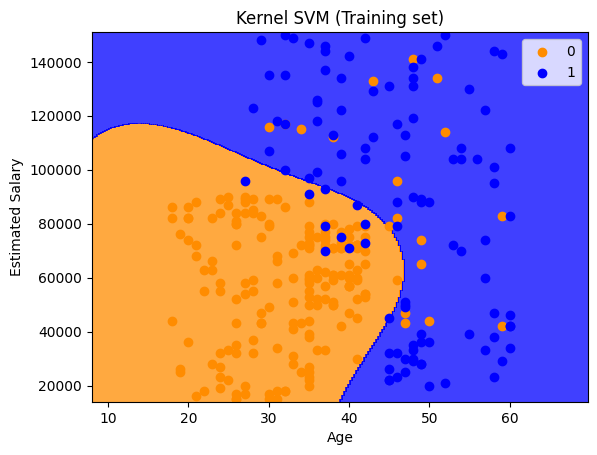

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_train), y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Kernel SVM (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

### Visualising the Test set results

<ipython-input-68-c46a0d26ff8b>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


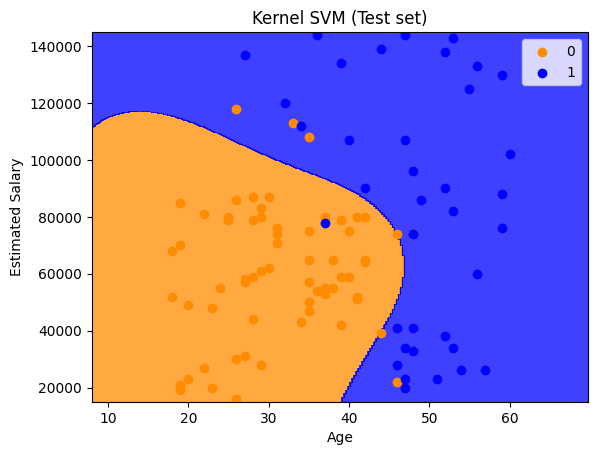

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_test), y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Kernel SVM (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

## Part 4: Model Evaluation

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[57  6]
 [ 1 36]]


In [ ]:
accuracy_score(y_test, y_pred)

0.93

## **ii) Algorithm 2: Naïve Bayes (NB)**

## Part 1: Implementation

### Training the NB model on the Training set

In [ ]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train)

GaussianNB()

## Part 2: Model Prediction

### Predicting the Test set results

In [ ]:
y_pred = classifier.predict(X_test)
print(np.concatenate((y_pred.reshape(len(y_pred), 1), y_test.reshape(len(y_test), 1)), 1))

[[1 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [0 1]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 1]]


## Part 3: Visualisation

### Visualising the Training set results

<ipython-input-73-028017606415>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


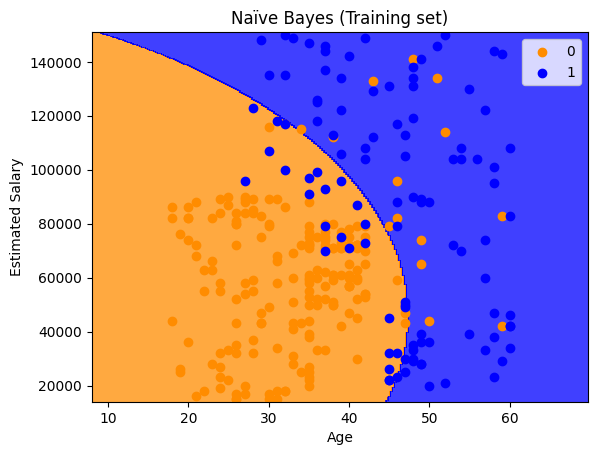

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_train), y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Naïve Bayes (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

### Visualising the Test set results

<ipython-input-74-ff55fb248a47>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


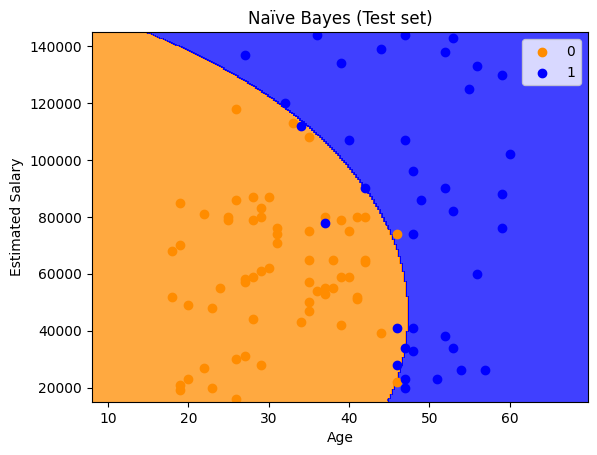

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_test), y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Naïve Bayes (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

## Part 4: Model Evaluation

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[61  2]
 [ 5 32]]


In [ ]:
accuracy_score(y_test, y_pred)

0.93

## **iii) Algorithm 3: Decision Tree (DT)**

## Part 1: Implementation

### Training the DT model on the Training set

In [ ]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(criterion = 'entropy', random_state = 42)
classifier.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

## Part 2: Model Prediction

### Predicting the Test set results

In [ ]:
y_pred = classifier.predict(X_test)
print(np.concatenate((y_pred.reshape(len(y_pred), 1), y_test.reshape(len(y_test), 1)), 1))

[[1 0]
 [0 1]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 0]
 [1 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 1]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 1]
 [0 0]
 [1 0]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [1 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 0]
 [1 1]
 [0 0]
 [1 1]
 [0 1]]


## Part 3: Visualisation

### Visualising the Training set results

<ipython-input-79-fb27fb9ebd3c>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


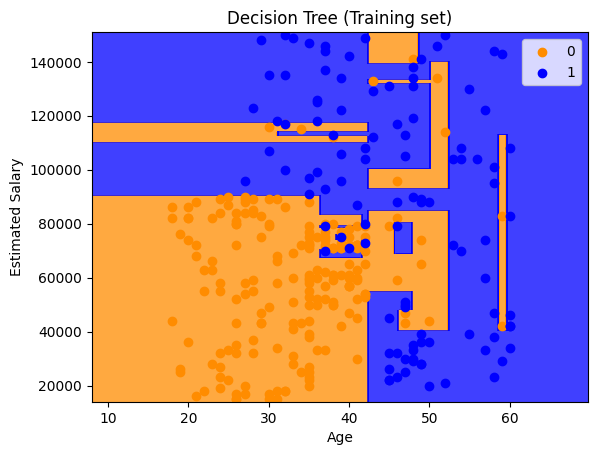

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_train), y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Decision Tree (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

### Visualising the Test set results

<ipython-input-80-0ab0482df32a>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


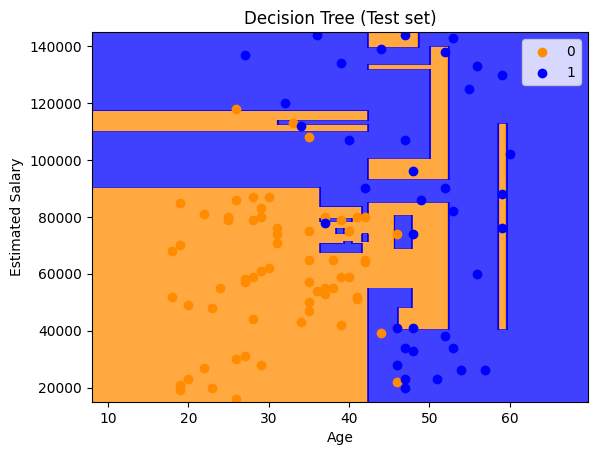

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_test), y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Decision Tree (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

### Visualising the Decision Tree

<Figure size 50000x10000 with 0 Axes>

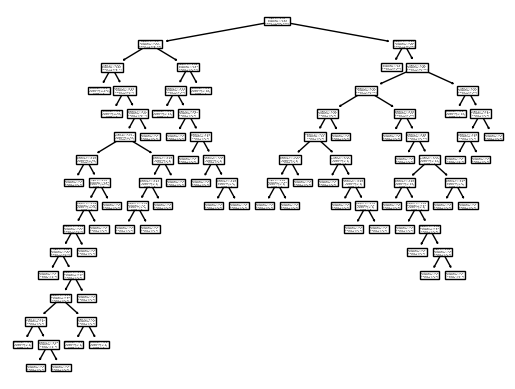

<Figure size 50000x10000 with 0 Axes>

In [ ]:
from sklearn import tree
tree.plot_tree(classifier, feature_names = ['Age', 'Salary'], class_names = ['0', '1'], precision = 2)
plt.figure(figsize = (500, 100), dpi = 100)

<Figure size 50000x10000 with 0 Axes>

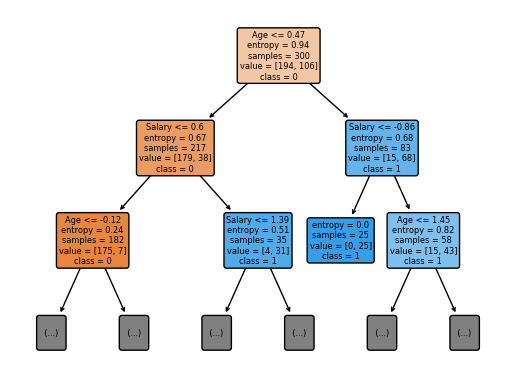

<Figure size 50000x10000 with 0 Axes>

In [ ]:
tree.plot_tree(classifier, max_depth = 2, feature_names = ['Age', 'Salary'], class_names = ['0', '1'], filled = True, rounded = True, precision = 2)
plt.figure(figsize = (500, 100), dpi = 100)

## Part 4: Model Evaluation

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[55  8]
 [ 9 28]]


In [ ]:
accuracy_score(y_test, y_pred)

0.83

## **iv) Algorithm 4: Random Forest (RF)**
## **[Ensemble ML Model (Bagging)]**

## Part 1: Implementation

### Training the RF model on the Training set

In [ ]:
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier(n_estimators = 10, criterion = 'entropy', random_state = 42)
classifier.fit(X_train, y_train)

RandomForestClassifier(criterion='entropy', n_estimators=10, random_state=42)

## Part 2: Model Prediction

### Predicting the Test set results

In [ ]:
y_pred = classifier.predict(X_test)
print(np.concatenate((y_pred.reshape(len(y_pred), 1), y_test.reshape(len(y_test), 1)), 1))

[[1 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 1]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [1 0]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [1 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 1]]


## Part 3: Visualisation

### Visualising the Training set results

<ipython-input-8-0df16fa1b987>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


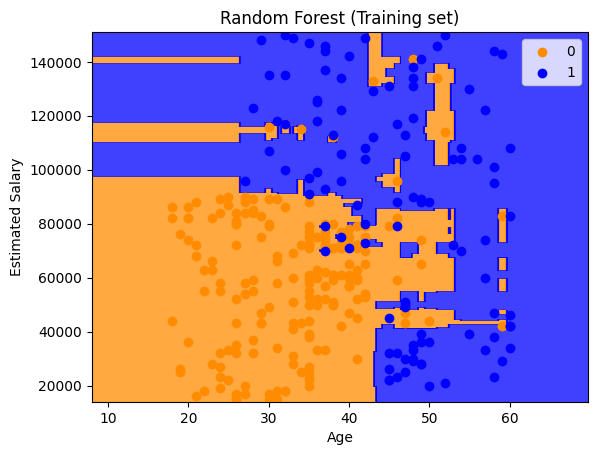

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_train), y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Random Forest (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

### Visualising the Test set results

<ipython-input-9-e6b3583db1aa>:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)


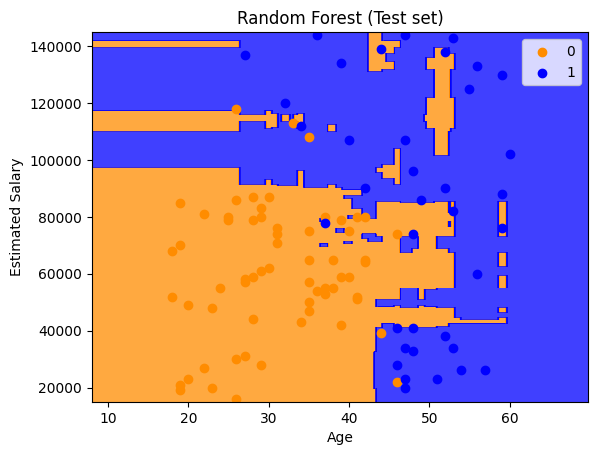

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_test), y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 250))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('darkorange', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('darkorange', 'blue'))(i), label = j)
plt.title('Random Forest (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

## Part 4: Model Evaluation

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[56  7]
 [ 7 30]]


In [ ]:
accuracy_score(y_test, y_pred)

0.86

## **Comparison of performance among the 7 algorithms**

Here, the best metric for comparison is the Accuracy Ratio (ACC) as we do not have an imbalanced dataset.

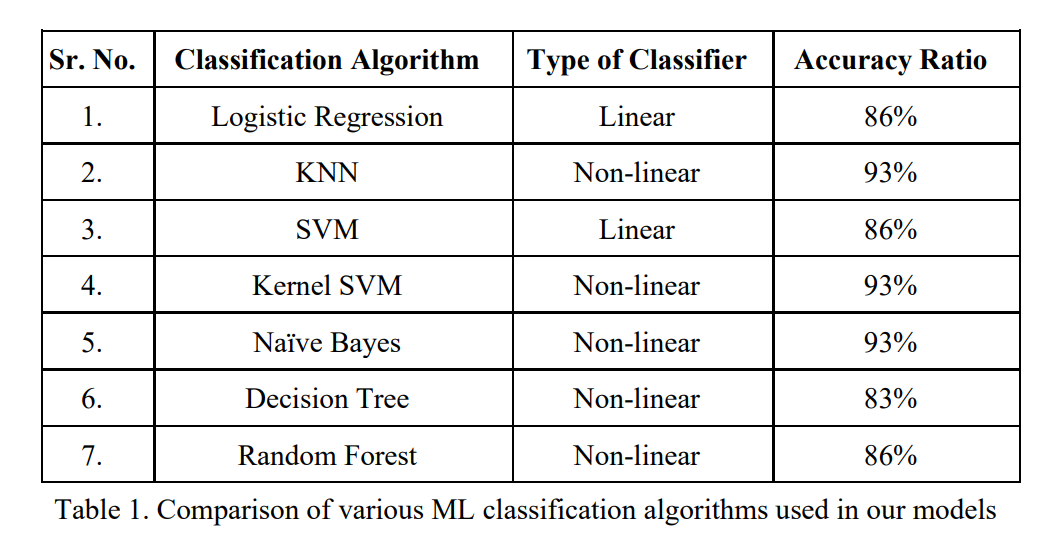

From the above table, we can see that non-linear classifiers generally perform better than linear classifiers (especially when the dataset is non-linearly separable). This holds true in our case as well with the '**KNN**', '**Kernel SVM**' and '**Naïve Bayes**' being the best performing algorithms (with an amazing accuracy ratio of 93%) followed by '**Logistic Regression**', '**SVM**' and '**Random Forest**' (with an 86% accuracy ratio) in this particular scenario. However, this may not always be the case as there is no definite answer as to which algorithm performs (classifies) the best. It is highly dependent on the dataset (scenario), how the ML algorithm is trained on it and fine-tuned, and the characteristics of both the dataset and the algorithm.